# Hanle ERA5 Wind Speed Calibration: Transferring ALMA Corrections

This notebook evaluates whether the wind speed calibration models trained on the **ALMA site (Andes)** can be successfully generalized to the **Hanle site (Himalayas)**. 

Specifically, we:
1. Load both ALMA and Hanle datasets (hourly-aligned).
2. Train three calibration systems on the **ALMA dataset**:
   - **Constant Offset**: $v_{\text{cal}} = v_{\text{ERA5}} + 4.0626$ m/s
   - **Global Linear Rescale**: $v_{\text{cal}} = 1.2986 \cdot v_{\text{ERA5}} + 3.3197$
   - **Smooth Ridge Regression with Lags**: Fits a Ridge model on 19 features (temporal lags, wind direction components, time harmonics).
3. Apply these ALMA-trained calibrations directly to the **Hanle ERA5 dataset**.
4. Compare their results against the Hanle ground observations to evaluate if they represent **over-corrections** or **mismatches**.

In [1]:
# ============================================================
# 1. IMPORTS & CONFIGURATION
# ============================================================
import os
import glob
import gc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

plt.style.use('default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Coordinates & Paths
ALMA_LAT, ALMA_LON = -23.029, -67.755
HANLE_LAT, HANLE_LON = 32.779, 78.964

CHILE_RAW = r"../../data/raw/chile"
INDIA_RAW = r"../../data/raw/HN Data Monthly"
REAL_DIR = r"../../data/processed/hanle_published"
ALMA_PUB_PATH = r"../../data/exports/alma_published_timeseries.csv"
OUTPUT_DIR = r"../../data/exports"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Environment and configuration loaded! [OK]")

Environment and configuration loaded! [OK]


In [2]:
# ============================================================
# 2. LOAD & ALIGN ALMA DATASETS
# ============================================================
print("Loading ALMA ground-based published timeseries...")
df_alma_pub = pd.read_csv(ALMA_PUB_PATH, parse_dates=['datetime']).dropna(subset=['speed'])

print("Loading ALMA ERA5 NetCDF files...")
chile_files = sorted(glob.glob(os.path.join(CHILE_RAW, "chile_*.nc")))
alma_records = []
for f in chile_files:
    with xr.open_dataset(f) as ds:
        point_ds = ds.sel(latitude=ALMA_LAT, longitude=ALMA_LON, method='nearest')
        u10 = point_ds['u10'].values
        v10 = point_ds['v10'].values
        ws10 = np.sqrt(u10**2 + v10**2)
        
        df_pt = pd.DataFrame({
            'datetime': pd.to_datetime(point_ds['valid_time'].values),
            'era5_speed': ws10,
            'era5_u10': u10,
            'era5_v10': v10
        })
        alma_records.append(df_pt)
df_alma_era5 = pd.concat(alma_records, ignore_index=True)

# Merge ALMA datasets
df_alma = pd.merge(df_alma_pub, df_alma_era5, on='datetime', how='inner').dropna(subset=['speed', 'era5_speed'])
df_alma = df_alma.sort_values('datetime').reset_index(drop=True)
print(f"ALMA aligned dataset size: {len(df_alma):,} records.")

Loading ALMA ground-based published timeseries...


Loading ALMA ERA5 NetCDF files...


ALMA aligned dataset size: 15,632 records.


In [3]:
# ============================================================
# 3. TRAIN CALIBRATION MODELS ON ALMA DATA
# ============================================================
print("Training ALMA calibrations...")

# Model A: Constant Offset (Adds +4.0626 m/s)
# Model B: Global Linear Fit
slope, intercept = np.polyfit(df_alma['era5_speed'], df_alma['speed'], 1)
print(f"  ALMA Global Linear Fit: ground_speed = {slope:.4f} * era5_speed + {intercept:.4f}")

# Model C: Smooth Ridge Regression
# Feature Engineering on ALMA
for lag in [1, 2]:
    df_alma[f'era5_speed_lag{lag}'] = df_alma['era5_speed'].shift(lag)
    df_alma[f'era5_speed_lead{lag}'] = df_alma['era5_speed'].shift(-lag)
    df_alma[f'era5_u10_lag{lag}'] = df_alma['era5_u10'].shift(lag)
    df_alma[f'era5_u10_lead{lag}'] = df_alma['era5_u10'].shift(-lag)
    df_alma[f'era5_v10_lag{lag}'] = df_alma['era5_v10'].shift(lag)
    df_alma[f'era5_v10_lead{lag}'] = df_alma['era5_v10'].shift(-lag)

df_alma['hour'] = df_alma['datetime'].dt.hour
df_alma['month'] = df_alma['datetime'].dt.month

h_rad = 2 * np.pi * df_alma['hour'] / 24.0
m_rad = 2 * np.pi * df_alma['month'] / 12.0
df_alma['sin_hour'] = np.sin(h_rad)
df_alma['cos_hour'] = np.cos(h_rad)
df_alma['sin_hour_2'] = np.sin(2 * h_rad)
df_alma['cos_hour_2'] = np.cos(2 * h_rad)
df_alma['sin_month'] = np.sin(m_rad)
df_alma['cos_month'] = np.cos(m_rad)

df_alma['ws_sin_hour'] = df_alma['era5_speed'] * df_alma['sin_hour']
df_alma['ws_cos_hour'] = df_alma['era5_speed'] * df_alma['cos_hour']
df_alma['ws_u10'] = df_alma['era5_speed'] * df_alma['era5_u10']
df_alma['ws_v10'] = df_alma['era5_speed'] * df_alma['era5_v10']

lag_cols = [c for c in df_alma.columns if 'lag' in c or 'lead' in c]
df_alma_clean = df_alma.dropna(subset=lag_cols).reset_index(drop=True)

X_cols = [
    'era5_speed', 'era5_u10', 'era5_v10',
    'era5_speed_lag1', 'era5_u10_lag1', 'era5_v10_lag1',
    'era5_speed_lead1', 'era5_u10_lead1', 'era5_v10_lead1',
    'sin_hour', 'cos_hour', 'sin_hour_2', 'cos_hour_2', 'sin_month', 'cos_month',
    'ws_sin_hour', 'ws_cos_hour', 'ws_u10', 'ws_v10'
]

reg = Ridge(alpha=1.0)
reg.fit(df_alma_clean[X_cols], df_alma_clean['speed'])
print(f"  ALMA Ridge Model Trained. R² Score: {reg.score(df_alma_clean[X_cols], df_alma_clean['speed']):.4f}")

Training ALMA calibrations...
  ALMA Global Linear Fit: ground_speed = 1.2986 * era5_speed + 3.3197
  ALMA Ridge Model Trained. R² Score: 0.6277


In [4]:
# ============================================================
# 4. LOAD & ALIGN HANLE DATASETS
# ============================================================
print("Loading and hourly resampling Hanle Real AWS observations...")
real_files = sorted(glob.glob(os.path.join(REAL_DIR, "hanle_published_*.csv")))
print(f"Found {len(real_files)} CSV files for Hanle.")

hourly_records = []
for f in real_files:
    df_m = pd.read_csv(f, usecols=['datetime_utc', 'wind_speed', 'u', 'v'])
    df_m['datetime_utc'] = pd.to_datetime(df_m['datetime_utc'])
    df_m = df_m.set_index('datetime_utc')
    
    u_h = df_m['u'].resample('1h').mean()
    v_h = df_m['v'].resample('1h').mean()
    speed_h = df_m['wind_speed'].resample('1h').mean()
    
    df_h = pd.DataFrame({
        'speed': speed_h,
        'u': u_h,
        'v': v_h
    }).dropna(subset=['speed'])
    
    hourly_records.append(df_h)
    del df_m
    gc.collect()

df_hanle_pub = pd.concat(hourly_records)
df_hanle_pub['direction'] = (270 - np.degrees(np.arctan2(df_hanle_pub['v'], df_hanle_pub['u']))) % 360
df_hanle_pub = df_hanle_pub.reset_index().rename(columns={'datetime_utc': 'datetime'})

print("Loading Hanle ERA5 NetCDF files...")
era5_files = sorted(glob.glob(os.path.join(INDIA_RAW, "india_*.nc")))
hanle_era5_records = []
for f in era5_files:
    with xr.open_dataset(f) as ds:
        point_ds = ds.sel(latitude=HANLE_LAT, longitude=HANLE_LON, method='nearest')
        u10 = point_ds['u10'].values
        v10 = point_ds['v10'].values
        ws10 = np.sqrt(u10**2 + v10**2)
        
        df_pt = pd.DataFrame({
            'datetime': pd.to_datetime(point_ds['valid_time'].values),
            'era5_speed': ws10,
            'era5_u10': u10,
            'era5_v10': v10
        })
        hanle_era5_records.append(df_pt)
df_hanle_era5 = pd.concat(hanle_era5_records, ignore_index=True)

# Merge Hanle datasets
df_hanle = pd.merge(df_hanle_pub, df_hanle_era5, on='datetime', how='inner').dropna(subset=['speed', 'era5_speed'])
df_hanle = df_hanle.sort_values('datetime').reset_index(drop=True)
print(f"Hanle aligned dataset size: {len(df_hanle):,} records.")

Loading and hourly resampling Hanle Real AWS observations...
Found 67 CSV files for Hanle.


Loading Hanle ERA5 NetCDF files...


Hanle aligned dataset size: 46,979 records.


In [5]:
# ============================================================
# 5. FEATURE ENGINEERING ON HANLE ERA5 & MODEL TRANSFER
# ============================================================
print("Applying ALMA-trained models to Hanle...")

# Model A: ALMA constant offset
df_hanle['era5_speed_offset'] = df_hanle['era5_speed'] + 4.0626

# Model B: ALMA global linear fit
df_hanle['era5_speed_linear'] = slope * df_hanle['era5_speed'] + intercept

# Model C: ALMA smooth Ridge regression
# Engineering features on Hanle data
df_hanle_feat = df_hanle.copy()
for lag in [1, 2]:
    df_hanle_feat[f'era5_speed_lag{lag}'] = df_hanle_feat['era5_speed'].shift(lag)
    df_hanle_feat[f'era5_speed_lead{lag}'] = df_hanle_feat['era5_speed'].shift(-lag)
    df_hanle_feat[f'era5_u10_lag{lag}'] = df_hanle_feat['era5_u10'].shift(lag)
    df_hanle_feat[f'era5_u10_lead{lag}'] = df_hanle_feat['era5_u10'].shift(-lag)
    df_hanle_feat[f'era5_v10_lag{lag}'] = df_hanle_feat['era5_v10'].shift(lag)
    df_hanle_feat[f'era5_v10_lead{lag}'] = df_hanle_feat['era5_v10'].shift(-lag)

df_hanle_feat['hour'] = df_hanle_feat['datetime'].dt.hour
df_hanle_feat['month'] = df_hanle_feat['datetime'].dt.month

h_rad = 2 * np.pi * df_hanle_feat['hour'] / 24.0
m_rad = 2 * np.pi * df_hanle_feat['month'] / 12.0
df_hanle_feat['sin_hour'] = np.sin(h_rad)
df_hanle_feat['cos_hour'] = np.cos(h_rad)
df_hanle_feat['sin_hour_2'] = np.sin(2 * h_rad)
df_hanle_feat['cos_hour_2'] = np.cos(2 * h_rad)
df_hanle_feat['sin_month'] = np.sin(m_rad)
df_hanle_feat['cos_month'] = np.cos(m_rad)

df_hanle_feat['ws_sin_hour'] = df_hanle_feat['era5_speed'] * df_hanle_feat['sin_hour']
df_hanle_feat['ws_cos_hour'] = df_hanle_feat['era5_speed'] * df_hanle_feat['cos_hour']
df_hanle_feat['ws_u10'] = df_hanle_feat['era5_speed'] * df_hanle_feat['era5_u10']
df_hanle_feat['ws_v10'] = df_hanle_feat['era5_speed'] * df_hanle_feat['era5_v10']

# Clean NaNs created at start/end of timeseries due to shifts
clean_mask = df_hanle_feat[lag_cols].notna().all(axis=1)
df_hanle_clean = df_hanle_feat[clean_mask].reset_index(drop=True)

# Predict Hanle speeds using the ALMA Ridge model
df_hanle_clean['era5_speed_ridge'] = reg.predict(df_hanle_clean[X_cols])
print(f"Calibrated Hanle records with Ridge regression model size: {len(df_hanle_clean):,} rows.")

Applying ALMA-trained models to Hanle...
Calibrated Hanle records with Ridge regression model size: 46,975 rows.


In [6]:
# ============================================================
# 6. EVALUATE TRANSFERRED COMPARISON METRICS ON HANLE SITE
# ============================================================
def calc_metrics(pred, truth):
    diff = pred - truth
    rmse = np.sqrt((diff ** 2).mean())
    bias = diff.mean()
    mae = diff.abs().mean()
    corr = truth.corr(pd.Series(pred, index=truth.index))
    return bias, mae, rmse, corr

# Use df_hanle_clean to align all metrics correctly on the same subset of records
truth = df_hanle_clean['speed']

metrics_orig = calc_metrics(df_hanle_clean['era5_speed'], truth)
metrics_offset = calc_metrics(df_hanle_clean['era5_speed_offset'], truth)
metrics_linear = calc_metrics(df_hanle_clean['era5_speed_linear'], truth)
metrics_ridge = calc_metrics(df_hanle_clean['era5_speed_ridge'], truth)

df_metrics = pd.DataFrame({
    'Metric': ['Mean Bias Error (MBE)', 'Mean Absolute Error (MAE)', 'Root Mean Square Error (RMSE)', 'Pearson Correlation (R)'],
    'Original ERA5': metrics_orig,
    'ALMA Offset-Adjusted': metrics_offset,
    'ALMA Linear-Rescaled': metrics_linear,
    'ALMA Ridge-Regression': metrics_ridge
})

print("=== Hanle Comparative Evaluation Table (ALMA Model Transfer) ===")
print(df_metrics.to_string(index=False))

# Percentile table
percentiles = [50, 90, 95, 99]
pub_pcts = [truth.quantile(p/100) for p in percentiles]
orig_pcts = [df_hanle_clean['era5_speed'].quantile(p/100) for p in percentiles]
offset_pcts = [df_hanle_clean['era5_speed_offset'].quantile(p/100) for p in percentiles]
linear_pcts = [df_hanle_clean['era5_speed_linear'].quantile(p/100) for p in percentiles]
ridge_pcts = [df_hanle_clean['era5_speed_ridge'].quantile(p/100) for p in percentiles]

df_pct = pd.DataFrame({
    'Percentile': [f'P{p}' for p in percentiles],
    'Ground-Based (m/s)': pub_pcts,
    'Original ERA5 (m/s)': orig_pcts,
    'ALMA Offset (m/s)': offset_pcts,
    'ALMA Linear (m/s)': linear_pcts,
    'ALMA Ridge (m/s)': ridge_pcts
})
print("\n=== Percentile Distribution Table ===")
print(df_pct.to_string(index=False))

=== Hanle Comparative Evaluation Table (ALMA Model Transfer) ===
                       Metric  Original ERA5  ALMA Offset-Adjusted  ALMA Linear-Rescaled  ALMA Ridge-Regression
        Mean Bias Error (MBE)      -3.227879              0.834721              0.596245              -0.453864
    Mean Absolute Error (MAE)       3.582851              3.701622              3.575972               3.249281
Root Mean Square Error (RMSE)       5.269181              4.247567              4.161032               4.325385
      Pearson Correlation (R)       0.392765              0.392765              0.392765               0.298442

=== Percentile Distribution Table ===
Percentile  Ground-Based (m/s)  Original ERA5 (m/s)  ALMA Offset (m/s)  ALMA Linear (m/s)  ALMA Ridge (m/s)
       P50            3.044585             1.572199           5.634799           5.361427          4.127526
       P90           11.835484             2.628576           6.691176           6.733278          7.608586
       P95  

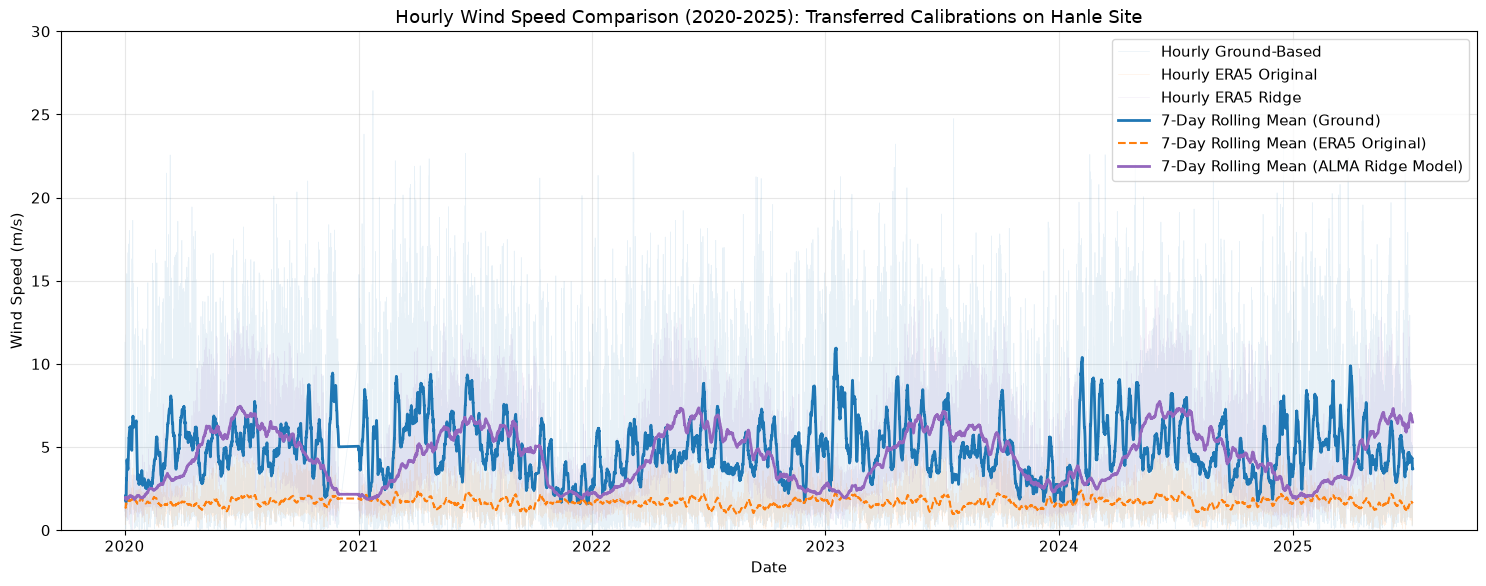

In [7]:
# ============================================================
# 7. PLOT TIME SERIES WITH 7-DAY ROLLING AVERAGE
# ============================================================
plt.figure(figsize=(15, 6))
plt.plot(df_hanle_clean['datetime'], df_hanle_clean['speed'], color='#1f77b4', alpha=0.1, label='Hourly Ground-Based', linewidth=0.5)
plt.plot(df_hanle_clean['datetime'], df_hanle_clean['era5_speed'], color='#ff7f0e', alpha=0.1, label='Hourly ERA5 Original', linewidth=0.5)
plt.plot(df_hanle_clean['datetime'], df_hanle_clean['era5_speed_ridge'], color='#9467bd', alpha=0.1, label='Hourly ERA5 Ridge', linewidth=0.5)

roll_window = 168
plt.plot(df_hanle_clean['datetime'], df_hanle_clean['speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#1f77b4', label='7-Day Rolling Mean (Ground)', linewidth=2.0)
plt.plot(df_hanle_clean['datetime'], df_hanle_clean['era5_speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#ff7f0e', label='7-Day Rolling Mean (ERA5 Original)', linewidth=1.5, linestyle='--')
plt.plot(df_hanle_clean['datetime'], df_hanle_clean['era5_speed_ridge'].rolling(roll_window, min_periods=24).mean(), 
         color='#9467bd', label='7-Day Rolling Mean (ALMA Ridge Model)', linewidth=2.0)

plt.title('Hourly Wind Speed Comparison (2020-2025): Transferred Calibrations on Hanle Site')
plt.xlabel('Date')
plt.ylabel('Wind Speed (m/s)')
plt.legend(loc='upper right')
plt.ylim(0, 30)
plt.tight_layout()
plt.savefig('../../data/exports/hanle_alma_cal_timeseries_comparison.png', dpi=150)
plt.show()

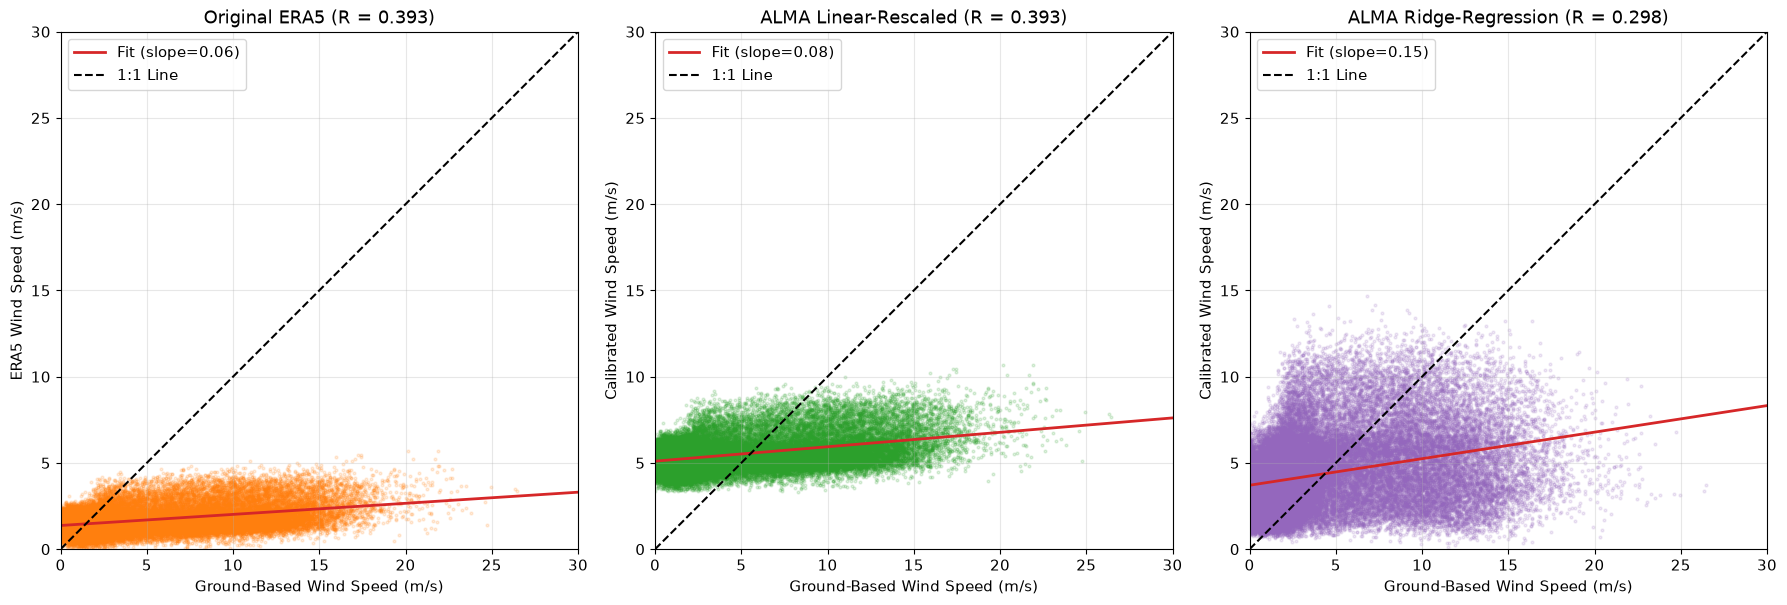

In [8]:
# ============================================================
# 8. SCATTER PLOTS FOR TRANSFERRED MODELS
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Panel A: Original
axes[0].scatter(df_hanle_clean['speed'], df_hanle_clean['era5_speed'], alpha=0.15, s=4, color='#ff7f0e')
slope_o, int_o = np.polyfit(df_hanle_clean['speed'], df_hanle_clean['era5_speed'], 1)
x_vals = np.linspace(0, 30, 100)
axes[0].plot(x_vals, slope_o * x_vals + int_o, color='#d62728', linewidth=2.0, label=f'Fit (slope={slope_o:.2f})')
axes[0].plot([0, 30], [0, 30], 'k--', label='1:1 Line')
axes[0].set_title(f'Original ERA5 (R = {metrics_orig[3]:.3f})')
axes[0].set_xlabel('Ground-Based Wind Speed (m/s)')
axes[0].set_ylabel('ERA5 Wind Speed (m/s)')
axes[0].set_xlim(0, 30)
axes[0].set_ylim(0, 30)
axes[0].set_aspect('equal', adjustable='box')
axes[0].legend(loc='upper left')

# Panel B: Linear Rescaled
axes[1].scatter(df_hanle_clean['speed'], df_hanle_clean['era5_speed_linear'], alpha=0.15, s=4, color='#2ca02c')
slope_l, int_l = np.polyfit(df_hanle_clean['speed'], df_hanle_clean['era5_speed_linear'], 1)
axes[1].plot(x_vals, slope_l * x_vals + int_l, color='#d62728', linewidth=2.0, label=f'Fit (slope={slope_l:.2f})')
axes[1].plot([0, 30], [0, 30], 'k--', label='1:1 Line')
axes[1].set_title(f'ALMA Linear-Rescaled (R = {metrics_linear[3]:.3f})')
axes[1].set_xlabel('Ground-Based Wind Speed (m/s)')
axes[1].set_ylabel('Calibrated Wind Speed (m/s)')
axes[1].set_xlim(0, 30)
axes[1].set_ylim(0, 30)
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend(loc='upper left')

# Panel C: Ridge
axes[2].scatter(df_hanle_clean['speed'], df_hanle_clean['era5_speed_ridge'], alpha=0.15, s=4, color='#9467bd')
slope_r, int_r = np.polyfit(df_hanle_clean['speed'], df_hanle_clean['era5_speed_ridge'], 1)
axes[2].plot(x_vals, slope_r * x_vals + int_r, color='#d62728', linewidth=2.0, label=f'Fit (slope={slope_r:.2f})')
axes[2].plot([0, 30], [0, 30], 'k--', label='1:1 Line')
axes[2].set_title(f'ALMA Ridge-Regression (R = {metrics_ridge[3]:.3f})')
axes[2].set_xlabel('Ground-Based Wind Speed (m/s)')
axes[2].set_ylabel('Calibrated Wind Speed (m/s)')
axes[2].set_xlim(0, 30)
axes[2].set_ylim(0, 30)
axes[2].set_aspect('equal', adjustable='box')
axes[2].legend(loc='upper left')

plt.tight_layout()
plt.savefig('../../data/exports/hanle_alma_cal_scatter_comparison.png', dpi=150)
plt.show()

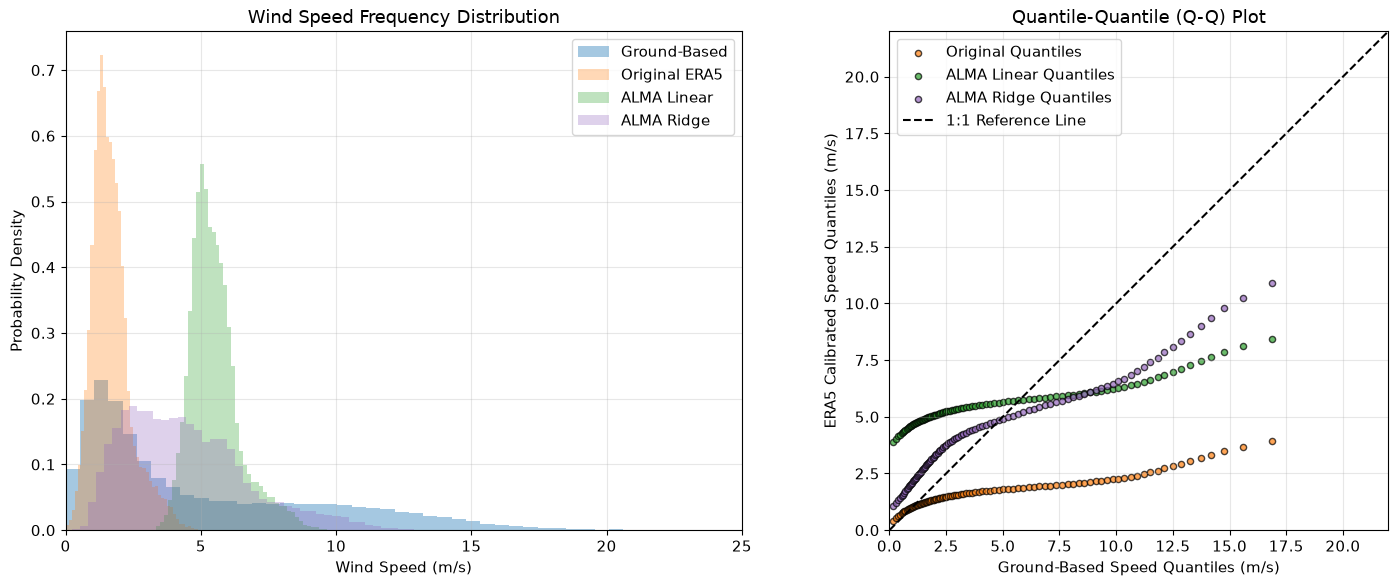

In [9]:
# ============================================================
# 9. DISTRIBUTION COMPARISON (HISTOGRAMS & Q-Q PLOT)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Histograms
axes[0].hist(df_hanle_clean['speed'], bins=50, color='#1f77b4', alpha=0.4, label='Ground-Based', density=True)
axes[0].hist(df_hanle_clean['era5_speed'], bins=50, color='#ff7f0e', alpha=0.3, label='Original ERA5', density=True)
axes[0].hist(df_hanle_clean['era5_speed_linear'], bins=50, color='#2ca02c', alpha=0.3, label='ALMA Linear', density=True)
axes[0].hist(df_hanle_clean['era5_speed_ridge'], bins=50, color='#9467bd', alpha=0.3, label='ALMA Ridge', density=True)
axes[0].set_title('Wind Speed Frequency Distribution')
axes[0].set_xlabel('Wind Speed (m/s)')
axes[0].set_ylabel('Probability Density')
axes[0].set_xlim(0, 25)
axes[0].legend()

# Panel B: Q-Q Plot
q_values = np.linspace(0.01, 0.99, 99)
q_pub = df_hanle_clean['speed'].quantile(q_values)
q_orig = df_hanle_clean['era5_speed'].quantile(q_values)
q_linear = df_hanle_clean['era5_speed_linear'].quantile(q_values)
q_ridge = df_hanle_clean['era5_speed_ridge'].quantile(q_values)

axes[1].scatter(q_pub, q_orig, color='#ff7f0e', edgecolor='k', s=20, alpha=0.7, label='Original Quantiles')
axes[1].scatter(q_pub, q_linear, color='#2ca02c', edgecolor='k', s=20, alpha=0.7, label='ALMA Linear Quantiles')
axes[1].scatter(q_pub, q_ridge, color='#9467bd', edgecolor='k', s=20, alpha=0.7, label='ALMA Ridge Quantiles')
axes[1].plot([0, 25], [0, 25], 'k--', label='1:1 Reference Line')
axes[1].set_title('Quantile-Quantile (Q-Q) Plot')
axes[1].set_xlabel('Ground-Based Speed Quantiles (m/s)')
axes[1].set_ylabel('ERA5 Calibrated Speed Quantiles (m/s)')
axes[1].set_xlim(0, 22)
axes[1].set_ylim(0, 22)
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend()

plt.tight_layout()
plt.savefig('../../data/exports/hanle_alma_cal_distribution_comparison.png', dpi=150)
plt.show()

--- Aligned Monthly Means (Excluding ground gaps) ---
 year  month  mean_pub  mean_orig  mean_offset  mean_linear  mean_ridge  count
 2020      1  4.371091   1.762561     5.825161     5.608638    1.999160    732
 2020      2  3.719269   1.682054     5.744654     5.504088    2.572235    697
 2020      3  5.961604   1.606395     5.668995     5.405836    3.194703    732
 2020      4  4.756311   1.465442     5.528042     5.222788    4.507703    684
 2020      5  5.027241   1.633906     5.696507     5.441563    5.958592    686
 2020      6  5.234970   1.746423     5.809023     5.587681    6.675386    708
 2020      7  5.616967   1.851640     5.914240     5.724320    6.679180    743
 2020      8  4.678220   1.691571     5.754170     5.516448    6.019712    735
 2020      9  5.523082   1.866277     5.928877     5.743327    5.399032    721
 2020     10  5.522193   1.872947     5.935547     5.751989    4.252473    745
 2020     11  5.205559   1.780932     5.843533     5.632496    2.838764    72

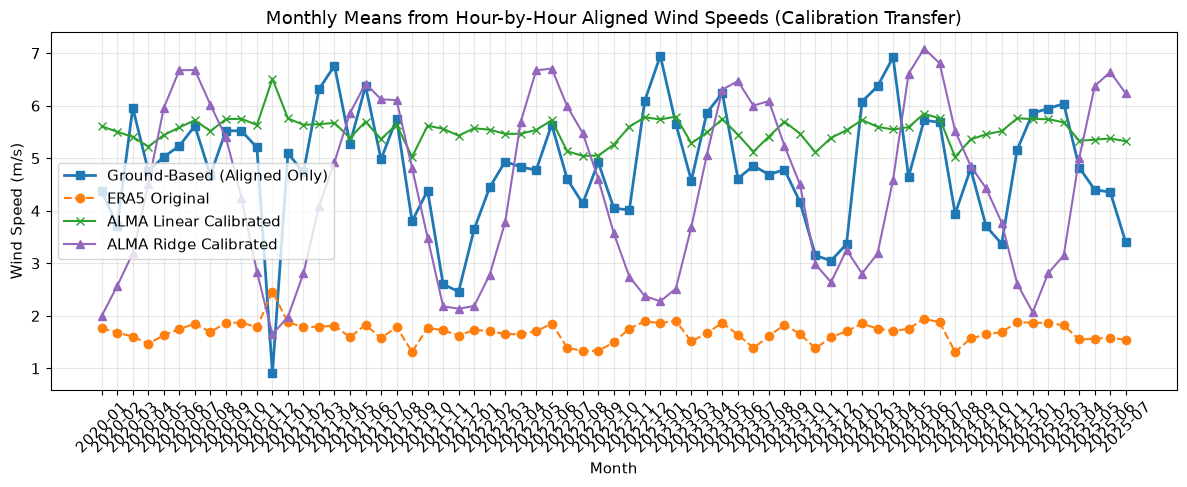

In [10]:
# ============================================================
# 10. MONTHLY MEANS COMPARISON OVER ALIGNED DATA
# ============================================================
df_hanle_clean['year'] = df_hanle_clean['datetime'].dt.year
df_hanle_clean['month'] = df_hanle_clean['datetime'].dt.month

monthly_aligned = df_hanle_clean.groupby(['year', 'month']).agg(
    mean_pub=('speed', 'mean'),
    mean_orig=('era5_speed', 'mean'),
    mean_offset=('era5_speed_offset', 'mean'),
    mean_linear=('era5_speed_linear', 'mean'),
    mean_ridge=('era5_speed_ridge', 'mean'),
    count=('speed', 'count')
).reset_index()

print("--- Aligned Monthly Means (Excluding ground gaps) ---")
print(monthly_aligned.to_string(index=False))

# Plot monthly means
plt.figure(figsize=(12, 5))
monthly_aligned['date_str'] = monthly_aligned['year'].astype(str) + '-' + monthly_aligned['month'].astype(str).str.zfill(2)
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_pub'], marker='s', color='#1f77b4', label='Ground-Based (Aligned Only)', linewidth=2.0)
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_orig'], marker='o', color='#ff7f0e', linestyle='--', label='ERA5 Original')
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_linear'], marker='x', color='#2ca02c', label='ALMA Linear Calibrated')
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_ridge'], marker='^', color='#9467bd', label='ALMA Ridge Calibrated')
plt.title('Monthly Means from Hour-by-Hour Aligned Wind Speeds (Calibration Transfer)')
plt.xlabel('Month')
plt.ylabel('Wind Speed (m/s)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../../data/exports/hanle_alma_cal_monthly_means.png', dpi=150)
plt.show()